# Prompt Guard – Baseline: TF-IDF + Logistic Regression

**Goal of this notebook:** train a first, simple machine learning model that reads a prompt
and decides **allow / warn / block**. It is our *baseline*: the reference point that every later,
more complex model (e.g. the NER model) has to beat.

**How the model works – in two steps**

1. **TF-IDF turns text into numbers.** A model cannot read text, it needs numbers.
   TF-IDF cuts every text into small pieces and gives every piece a weight:
   - **TF (term frequency):** how often does the piece occur *in this text*? Frequent → higher weight.
   - **IDF (inverse document frequency):** how rare is the piece *across all texts*?
     Pieces that occur everywhere (like `" der "`) are not informative → low weight;
     rare pieces (like `"@gmai"`) are informative → high weight.

   Every text becomes one long row of numbers (one column per piece) – most of them 0.
2. **Logistic Regression makes the decision.** It learns one weight per piece and class
   (e.g. *"`DE89` makes block more likely"*), adds up the weights of the pieces in a text and
   turns the sums into probabilities for allow / warn / block. The class with the highest probability wins.

**Why character pieces instead of words?** We cut the text into *character n-grams* –
sequences of 2 to 5 characters, e.g. `"@gm"`, `"mail"`, `"DE89"`. PII is mostly recognisable by
its *shape* (an `@` with a domain, a country code followed by digits, groups of 4 digits), not by
a specific word. With whole words, every new phone number or IBAN would be an unknown "word".

**Structure**
1. Setup · 2. Load the data · 3. A look at TF-IDF · 4. Turn all texts into numbers ·
5. Train & tune on validation · 6. Evaluate the best model · 7. Per language ·
8. Response time · 9. Error analysis · 10. What has the model learned? ·
11. Try your own prompts · 12. Save the model & log to MLflow · 13. Conclusion

> **Rule:** we train on `train`, choose settings on `validation` and do **not** touch `test`.
> The test set is used only once at the very end, for the final comparison of all models.

## 1. Setup

Imports, a few settings and the connection to our shared helper file `src/data_utils.py`,
which guarantees that all models use the same split and the same allow / warn / block labels.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn = the standard Python library for "classic" machine learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,      # precision / recall / F1 per class in one table
    confusion_matrix,           # table: true class vs. predicted class
    f1_score,
    recall_score,
)

# Make our own helper file src/data_utils.py importable ("../src" = one folder up, then into src)
sys.path.append("../src")
from data_utils import load_all_splits, split_fingerprint, load_policy

# --- Settings -------------------------------------------------------------------
SEED = 42                                  # same seed as for the split -> reproducible results
CLASSES = ["allow", "warn", "block"]       # fixed order for all tables and charts
MODEL_DIR = Path("../models")              # where the trained model is saved

# --- Chart style (same as in the preparation notebook) ------------------------------
BLUE = "#2a78d6"
ORANGE = "#eb6834"
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Setup done.")

Setup done.


## 2. Load the data

`load_all_splits()` reads the four language files, keeps the texts of each split and adds the
column `decision` (allow / warn / block) from `config/policy.yaml`.
The **fingerprint** is a short code of the split file – if two people get the same fingerprint,
they are guaranteed to use exactly the same split.

In [2]:
splits = load_all_splits()
train = splits["train"]
val = splits["validation"]
# Note: we deliberately do NOT create a variable for the test set here.

SPLIT_FINGERPRINT = split_fingerprint()
print("Split fingerprint:", SPLIT_FINGERPRINT)

# How many texts per split and per decision?
overview = pd.DataFrame({
    "train": train["decision"].value_counts(),
    "validation": val["decision"].value_counts(),
}).reindex(CLASSES)
overview.loc["total"] = overview.sum()
display(overview)

Split fingerprint: 6afd6a257de1


,train,validation
decision,,
allow,11471,2457
warn,88928,19055
block,46056,9868
total,146455,31380


For the model we only need two columns:
- **`X` = input** → the prompt text (`source_text`)
- **`y` = target** → the correct decision (`decision`)

In [3]:
X_train, y_train = train["source_text"], train["decision"]
X_val, y_val = val["source_text"], val["decision"]

# One example, so we can see what the model gets as input and what it should learn
print("Input :", X_train.iloc[0])
print("Target:", y_train.iloc[0])

Input : 'Exkursionsupdate: Wir werden uns in Northeast Richtung Wildreservat begeben. Bitte melden Sie sich am Basislager bei [-21.1529,-129.6237] zur Anmeldung.'
Target: warn


## 3. A look at TF-IDF on a tiny example

Before we use TF-IDF on 146,000 texts, we look at what it does with **one short sentence**.
`analyzer="char_wb"` means: character n-grams, but only *inside* words
(`wb` = word boundaries; the space around a word is kept as a marker, shown as `" "`).

In [4]:
demo = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
demo.fit(["Mail to max@gmx.de"])

# get_feature_names_out() lists all pieces ("n-grams") the vectorizer has found
pieces = demo.get_feature_names_out()
print(f"{len(pieces)} pieces, for example:")
print(list(pieces[:25]))

55 pieces, for example:
[' m', ' ma', ' mai', ' mail', ' max', ' max@', ' t', ' to', ' to ', '.d', '.de', '.de ', '@g', '@gm', '@gmx', '@gmx.', 'ai', 'ail', 'ail ', 'ax', 'ax@', 'ax@g', 'ax@gm', 'de', 'de ']


## 4. Turn all texts into numbers

Now the real vectorizer. The most important settings:

| Setting | Value | Meaning |
|---|---|---|
| `analyzer` | `"char_wb"` | character n-grams inside words (see above) |
| `ngram_range` | `(2, 5)` | pieces of 2 to 5 characters |
| `min_df` | `5` | ignore pieces that occur in fewer than 5 texts (mostly random noise, e.g. parts of one single password) |
| `max_features` | `300_000` | keep at most the 300,000 most frequent pieces → limits memory and training time |
| `sublinear_tf` | `True` | a piece that occurs 10× counts more than 1×, but not 10× as much (uses the logarithm) |
| `dtype` | `float32` | store the numbers with less precision → half the memory, no relevant loss |

**Important:** the vectorizer is fitted (`fit`) **only on train**. It learns the list of pieces
and their IDF weights from the training texts and then only *applies* (`transform`) this to
validation. If we fitted it on validation too, information from validation would leak into
training (*data leakage*) and the results would look better than they are.

In [5]:
vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 5),
    min_df=5,
    max_features=300_000,
    sublinear_tf=True,
    dtype=np.float32,
)

start = time.perf_counter()
X_train_vec = vectorizer.fit_transform(X_train)   # learn the pieces on train AND convert train
X_val_vec = vectorizer.transform(X_val)           # only convert validation (no learning!)
print(f"Vectorising took {time.perf_counter() - start:.0f} s")

# The result is a "sparse matrix": rows = texts, columns = pieces.
# Sparse = only the non-zero values are stored, because almost all values are 0.
print("Train matrix:     ", X_train_vec.shape, "(texts x pieces)")
print("Validation matrix:", X_val_vec.shape)
nonzero_per_text = X_train_vec.getnnz(axis=1).mean()
print(f"On average a text uses {nonzero_per_text:.0f} of {X_train_vec.shape[1]:,} pieces")

Vectorising took 154 s
Train matrix:      (146455, 300000) (texts x pieces)
Validation matrix: (31380, 300000)
On average a text uses 490 of 300,000 pieces


### Turning text into numbers with TF-IDF

Logistic regression needs numbers as input. We use `TfidfVectorizer` to turn each prompt into a row of numbers. Each column represents a short character fragment, such as `@gm` or `passw`.

#### What do the settings mean, and why did we choose them?

| Setting | What it does | Why we chose it |
|---|---|---|
| `analyzer="char_wb"` | Splits text into overlapping character fragments within word boundaries. For example, `max@gmx.de` contains fragments such as `@gm` and `.de`. | Different email addresses or identifiers can share useful fragments. The model can use a fragment it has seen before even when the full address is new. |
| `ngram_range=(2, 5)` | Creates fragments that are 2, 3, 4, or 5 characters long. | Short fragments such as `@g` can occur in many examples. Longer fragments such as `passw` give more specific clues. The range gives the model both kinds of information. |
| `min_df=5` | Keeps a fragment only if it appears in at least **five different training prompts**. Five repetitions in one prompt still count as one prompt. | This filters out very rare fragments, such as a random sequence found in a single synthetic password. The trade-off is that some useful but rare fragments may also be filtered out. |
| `max_features=300_000` | Keeps up to **300,000 of the most frequent fragments** that meet the minimum frequency requirement. | This limits the size of the feature matrix and the amount of computation. In this run, the vectorizer reached that limit. |
| `sublinear_tf=True` | Reduces the effect of repeating the same fragment within a prompt. Before applying IDF and normalization, one occurrence has a term-frequency value of `1`, while ten occurrences have a value of about `3.3`. | Repeating the same email address ten times still gives the model a stronger signal, but it should carry less than ten times the weight of a single occurrence. |
| `dtype=np.float32` | Stores each TF-IDF value using **4 bytes**. The `float64` format uses 8 bytes per value. | This reduces the memory needed to store the feature values across all prompts. |

These values were a **practical starting configuration** for the baseline. We kept them fixed while comparing different values of `C` for logistic regression.

#### Why do we use `fit_transform` on training and `transform` on validation?

1. **`fit_transform(X_train)` learns and converts.** The vectorizer learns which fragments to keep and how common or rare they are across the training prompts. It then converts the training prompts into numbers.
2. **`transform(X_val)` converts using what was already learned.** The validation prompts use the same columns and IDF weights. For example, if column 12 means `@gm` in training, it also means `@gm` in validation. New fragments outside the learned vocabulary are skipped.

Fitting on training data only prevents **data leakage**. If the validation prompts were included in `fit`, they could influence which fragments the model uses and how those fragments are weighted, even if we kept their `allow`, `warn`, and `block` labels hidden.

#### What do the output numbers mean?

| Output | How to read it |
|---|---|
| **154 seconds** | The time to fit the vectorizer and convert both the training and validation prompts. |
| **Training matrix `(146455, 300000)`** | 146,455 training prompts represented using 300,000 feature columns. |
| **Validation matrix `(31380, 300000)`** | 31,380 validation prompts represented using the same 300,000 columns. |
| **About 490 non-zero values per training prompt** | On average, only about 490 of the 300,000 columns have a value for a given prompt. |

Most entries are zero because each prompt contains only a small fraction of the learned fragments. A **sparse matrix** saves memory by storing the non-zero values and their positions.


## 5. Train the model and choose the best setting on validation

Logistic Regression has one important setting: **`C`** (regularisation strength).
- **small `C`** → the model is kept simple, weights stay small → may *underfit* (learns too little)
- **large `C`** → the model may follow the training data very closely → may *overfit*
  (learns the training texts by heart and works worse on new texts)

We try a few values, train on `train` and measure on `validation`. Two more settings:
- `class_weight="balanced"`: *allow* is only ~8 % of the texts. Without this setting the model
  could almost ignore allow. "balanced" makes mistakes on rare classes count more.
- `max_iter=1000`: the model is trained step by step; this is the maximum number of steps.

**Which metrics do we look at?**
- **Recall (block):** of all texts that *should* be blocked, how many did the model block?
  This is the most important number: a missed block (e.g. an IBAN sent to an external AI) is the most expensive mistake.
- **Macro F1:** the F1 score (balance of precision and recall) per class, then the simple average over
  the three classes. "Macro" means every class counts the same, so the small class allow is not ignored.

In [6]:
C_VALUES = [1.0, 3.0, 10.0]

results = []      # one row per tried C value
models = {}       # keep the trained models, so we do not have to train the best one again

for C in C_VALUES:
    model = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=1000,
        random_state=SEED,
    )
    start = time.perf_counter()
    model.fit(X_train_vec, y_train)                # learn the weights on train
    train_seconds = time.perf_counter() - start

    y_pred = model.predict(X_val_vec)              # predict validation
    results.append({
        "C": C,
        "macro F1": f1_score(y_val, y_pred, average="macro"),
        # labels=["block"] -> recall of the class block only
        "recall block": recall_score(y_val, y_pred, labels=["block"], average="macro"),
        "recall allow": recall_score(y_val, y_pred, labels=["allow"], average="macro"),
        "training time (s)": round(train_seconds),
    })
    models[C] = model
    print(f"C={C}: done in {train_seconds:.0f} s")

results = pd.DataFrame(results).set_index("C").round(4)
display(results)

C=1.0: done in 203 s


C=3.0: done in 252 s


C=10.0: done in 235 s


,macro F1,recall block,recall allow,training time (s)
C,,,,
1.0,0.8303,0.9031,0.9280,203
3.0,0.8553,0.9124,0.9052,252
10.0,0.8702,0.9178,0.8787,235


We choose the `C` with the best **macro F1** on validation.
(If two values are almost equal, the smaller `C` is the safer choice, because the simpler model usually generalises better.)

In [7]:
BEST_C = results["macro F1"].idxmax()     # idxmax = the C (index) with the highest macro F1
best_model = models[BEST_C]
print("Best C:", BEST_C)

# Pack vectorizer + model into ONE object (a "pipeline").
# Advantage: later we can give it raw text and it does both steps itself.
pipeline = Pipeline([("tfidf", vectorizer), ("logreg", best_model)])

Best C: 10.0


## 6. Evaluate the best model on validation

**How to read the report**
- **precision:** of all texts the model put into a class, how many really belong there?
  (low precision for block = many *false alarms*: harmless prompts get blocked)
- **recall:** of all texts that really belong to a class, how many did the model find?
  (low recall for block = *missed* sensitive content)
- **f1-score:** a combination of precision and recall (1.0 = perfect)
- **support:** number of texts of this class in validation

In [8]:
y_val_pred = pipeline.predict(X_val)
print(classification_report(y_val, y_val_pred, labels=CLASSES, digits=3))

              precision    recall  f1-score   support

       allow      0.675     0.879     0.764      2457
        warn      0.945     0.910     0.927     19055
       block      0.922     0.918     0.920      9868

    accuracy                          0.910     31380
   macro avg      0.847     0.902     0.870     31380
weighted avg      0.916     0.910     0.912     31380



## TF-IDF + Logistic Regression — Validation Results

The model assigned one decision to each of **31,380 validation prompts**. The report compares those predictions with the expected decisions under the project policy.

### How to read the columns

- **Support** is the number of prompts that should receive a particular decision.
- **Precision** asks, “When the model chose this decision, how often was it right?”
- **Recall** asks, “Of all the prompts that should have received this decision, how many did the model find?”
- **F1 score** combines precision and recall into a score from 0 to 1. A low value for either one pulls the F1 score down.

The report shows decimals. For example, `0.918` means **91.8%**.

| Decision | Precision | Recall | F1 score | Support |
|---|---:|---:|---:|---:|
| `allow` | 67.5% | 87.9% | 0.764 | 2,457 |
| `warn` | 94.5% | 91.0% | 0.927 | 19,055 |
| `block` | 92.2% | 91.8% | 0.920 | 9,868 |

### What do the results mean for each decision?

**`block` — Most prompts that needed a block were caught.** The model correctly blocked **9,057 prompts**. You can use that same number to understand both scores:

- **Recall:** Of the **9,868 prompts that should have been blocked**, the model blocked **9,057** correctly. That is **91.8%**. Of the remaining **811**, it warned on **743** and allowed **68** through.
- **Precision:** Of the **9,821 prompts the model actually blocked**, **9,057** should have been blocked. That is **92.2%**. The other **764** were false blocks.

**`warn` — This class has the highest F1 score.** When the model issued a warning, it was right **94.5%** of the time. It found **91.0%** of the prompts that should have received a warning.

**`allow` — This class has the lowest F1 score.** The model correctly allowed **2,159 of the 2,457** prompts that should have been allowed. That gives it **87.9% recall**. It allowed **3,198 prompts** in total, including **971** that should have received a warning and **68** that should have been blocked. That is why its `allow` precision is lower at **67.5%**.

### What do the summary rows mean?

| Summary | Result | How to read it |
|---|---:|---|
| **Accuracy** | **91.0%** | The model made **28,559 correct decisions out of 31,380**. |
| **Macro average F1** | **0.870** | Each class counts equally. The weaker `allow` score has the same influence as the stronger `warn` and `block` scores. |
| **Weighted average F1** | **0.912** | Classes with more prompts count more. `warn` is the largest class and has a high F1 score, so it pulls this average up. |

For PromptGuard, **block recall** answers how often the model catches prompts that the policy says to stop. **Allow precision** answers how often the model is right when it lets a prompt through. These two scores show where errors occur even when overall accuracy is high.

The **confusion matrix** shows where the model goes wrong: rows = true class, columns = predicted class.
The diagonal (top left → bottom right) are the correct decisions, everything else is a mistake.
The most dangerous cells are **true block → predicted allow/warn** (sensitive content gets through).
We show the counts and, in brackets, the share of the row in %.

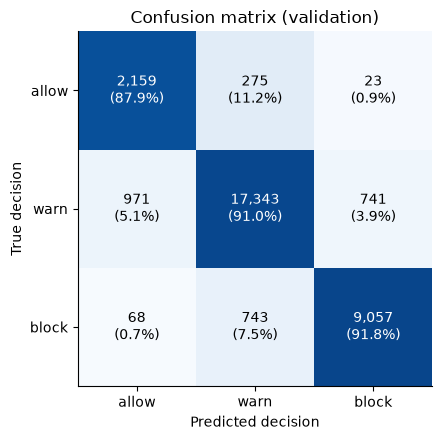

In [9]:
cm = confusion_matrix(y_val, y_val_pred, labels=CLASSES)
cm_share = cm / cm.sum(axis=1, keepdims=True)     # divide every row by its total -> share per true class

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm_share, cmap="Blues", vmin=0, vmax=1)   # colour = share of the row
for i in range(len(CLASSES)):           # i = row (true class)
    for j in range(len(CLASSES)):       # j = column (predicted class)
        colour = "white" if cm_share[i, j] > 0.6 else "black"   # readable on dark and light cells
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_share[i, j]:.1%})", ha="center", va="center", color=colour)
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("Predicted decision")
ax.set_ylabel("True decision")
ax.set_title("Confusion matrix (validation)")
ax.grid(False)
plt.tight_layout()
plt.show()

## 7. Results per language

Our company is German, so the result for `de` matters most. We calculate the key metrics separately for every language.

In [10]:
rows = []
for language, part in val.assign(pred=y_val_pred).groupby("language"):
    rows.append({
        "language": language,
        "texts": len(part),
        "macro F1": f1_score(part["decision"], part["pred"], average="macro"),
        "recall block": recall_score(part["decision"], part["pred"], labels=["block"], average="macro"),
        "recall allow": recall_score(part["decision"], part["pred"], labels=["allow"], average="macro"),
    })
per_language = pd.DataFrame(rows).set_index("language").round(4)
display(per_language)

,texts,macro F1,recall block,recall allow
language,,,,
de,7922,0.8776,0.9118,0.8813
en,6522,0.8554,0.9186,0.8553
fr,9292,0.8765,0.9221,0.8930
it,7644,0.8683,0.9180,0.8800


## TF-IDF + Logistic Regression — Results by Language

This table shows how the model performed on the **validation prompts** in each language. `texts` is the total number of prompts evaluated for that language.

### How to read the scores

- **Macro F1** summarizes performance across `allow`, `warn`, and `block`. Each of the three decisions counts equally.
- **Recall block** asks, “Of the prompts that should have been blocked, how many did the model actually block?”
- **Recall allow** asks, “Of the prompts that should have been allowed, how many did the model actually allow?”

### What do the results show?

| Language | Prompts | Macro F1 | Block recall | Allow recall |
|---|---:|---:|---:|---:|
| German (`de`) | 7,922 | **0.8776** | 91.18% | 88.13% |
| English (`en`) | 6,522 | 0.8554 | 91.86% | 85.53% |
| French (`fr`) | 9,292 | 0.8765 | **92.21%** | **89.30%** |
| Italian (`it`) | 7,644 | 0.8683 | 91.80% | 88.00% |

**German has the highest Macro F1.** This means it has the best average F1 across the three decisions in this validation run. Its block recall of **91.18%** means the model correctly blocked about **91 out of every 100 German prompts that should have been blocked**. The percentage uses only the German block cases within the 7,922 prompts.

**French has the highest block recall and allow recall.** The model caught **92.21%** of French prompts that needed a block and allowed **89.30%** of French prompts that should have been allowed.

**English has the lowest Macro F1 and allow recall.** Its block recall is still close to the other languages. So if we focus on blocking, the model performs similarly across all four languages, with block recall ranging from **91.18% to 92.21%**.

## 8. Response time

Prompt Guard sits between the employee and the AI service, so it must be fast.
We measure how long the model needs for **one single prompt** – this is the realistic case in the later API
(one request = one prompt). We repeat it for 1,000 prompts and look at the median and the 95th percentile
(95 % of the prompts are faster than this value).

In [11]:
sample = X_val.sample(1000, random_state=SEED).tolist()

times_ms = []
for prompt in sample:
    start = time.perf_counter()
    pipeline.predict([prompt])                         # a list with ONE prompt
    times_ms.append((time.perf_counter() - start) * 1000)

LATENCY_MEDIAN_MS = float(np.median(times_ms))
LATENCY_P95_MS = float(np.percentile(times_ms, 95))
print(f"Median: {LATENCY_MEDIAN_MS:.2f} ms per prompt")
print(f"95th percentile: {LATENCY_P95_MS:.2f} ms per prompt")

Median: 1.93 ms per prompt
95th percentile: 3.06 ms per prompt


## 9. Error analysis: which block cases did the model miss?

Numbers tell us *how many* mistakes there are, examples tell us *why*. We look at texts that should be
**block** but were predicted as something else, together with the PII labels they contain.

In [12]:
policy = load_policy()

missed = val.assign(pred=y_val_pred)
missed = missed[(missed["decision"] == "block") & (missed["pred"] != "block")]
print(f"Missed block texts: {len(missed):,} of {(y_val == 'block').sum():,}")

# Which block labels are in the missed texts? (shows which PII types the model struggles with)
block_labels = [
    entry["label"]
    for mask in missed["privacy_mask"]
    for entry in mask
    if policy["label_to_decision"].get(entry["label"]) == "block"
]
display(pd.Series(block_labels).value_counts().to_frame("count in missed texts"))

Missed block texts: 811 of 9,868


,count in missed texts
PASSWORD,354
ACCOUNTNUMBER,157
SSN,150
PIN,88
CREDITCARDCVV,45
MASKEDNUMBER,10
IBAN,8
CREDITCARDNUMBER,7


In [13]:
# Three examples: the text, what the model predicted, and the block-relevant PII in it
for _, row in missed.sample(min(3, len(missed)), random_state=SEED).iterrows():
    block_pii = [
        f"{e['label']}={e['value']!r}"
        for e in row["privacy_mask"]
        if policy["label_to_decision"].get(e["label"]) == "block"
    ]
    print(f"[{row['language']}] predicted: {row['pred']}")
    print("text:     ", row["source_text"])
    print("block PII:", ", ".join(block_pii))
    print()

[en] predicted: allow
text:      Patient 22 years old from 4417 was particularly interesting. With green and Female, they spun intriguing tales of their past. Made sure to keep their data safe with a strong zTQnEh7zpb1c.
block PII: PASSWORD='zTQnEh7zpb1c'

[fr] predicted: warn
text:      Pouvez-vous s'il vous plaît confirmer les frais de votre 799, Jo?
block PII: CREDITCARDCVV='799'

[en] predicted: warn
text:      Dear Direct Data Officer, attached herein is the details of academic competition due to take off at suite Suite 648, where we encourage that participants maintain their 7b2nodCbZB0Q given for registration purposes.
block PII: PASSWORD='7b2nodCbZB0Q'



## 10. What has the model learned?

A big advantage of Logistic Regression: we can look inside. For every class the model has one weight per piece.
**High positive weight** = this piece makes the class more likely. We show the 15 strongest pieces per class.

C:\Users\annis\AppData\Local\Temp\ipykernel_43816\693342419.py:13: UserWarning: Glyph 65020 (\N{RIAL SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


C:\Users\annis\MWI_AIOps\AIOps_PromptGuard\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 65020 (\N{RIAL SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


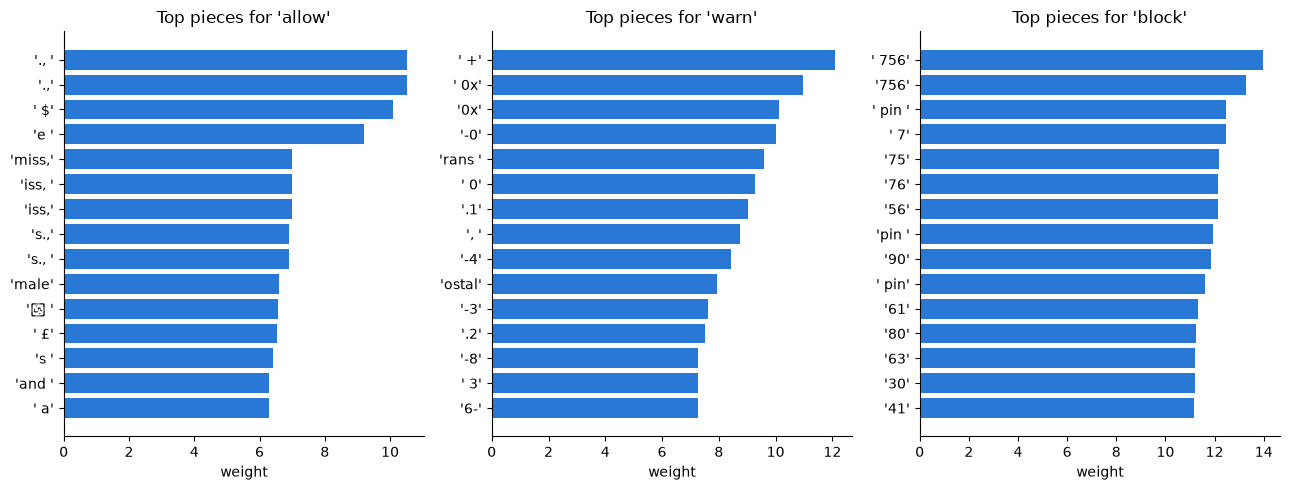

In [14]:
feature_names = vectorizer.get_feature_names_out()

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, cls in zip(axes, CLASSES):
    # best_model.classes_ is the order of the classes inside the model; find the row of this class
    row = list(best_model.classes_).index(cls)
    weights = best_model.coef_[row]
    top = np.argsort(weights)[-15:]            # positions of the 15 largest weights (ascending)
    # repr() shows spaces in the pieces, e.g. ' de' instead of de
    ax.barh([repr(feature_names[i]) for i in top], weights[top], color=BLUE)
    ax.set_title(f"Top pieces for '{cls}'")
    ax.set_xlabel("weight")
plt.tight_layout()
plt.show()

## 11. Try your own prompts

The dataset is synthetic, so it is important to check the model on prompts that look like real
ones from our company. Change or add prompts in the list and run the cell again.
`predict_proba` gives the probability of every class, so we also see how *sure* the model is.

In [15]:
my_prompts = [
    "Fasse bitte diesen Text über unsere neue Urlaubsregelung zusammen.",
    "Schreibe eine E-Mail an anna.schmidt@firma.de wegen des Termins am Montag.",
    "Bitte überweise 500 EUR auf DE89 3704 0044 0532 0130 00.",
    "Mein Passwort für das Portal ist Sommer2024! – kannst du prüfen, ob es sicher ist?",
    "Erstelle eine Tabelle mit den Umsätzen 2023 für die Regionen Nord und Süd.",
]

probabilities = pipeline.predict_proba(my_prompts)
result = pd.DataFrame(probabilities, columns=pipeline.classes_)[CLASSES].round(3)
result.insert(0, "prediction", pipeline.predict(my_prompts))
result.insert(0, "prompt", my_prompts)
with pd.option_context("display.max_colwidth", 80):
    display(result)

,prompt,prediction,allow,warn,block
0,Fasse bitte diesen Text über unsere neue Urlaubsregelung zusammen.,allow,0.920,0.077,0.002
1,Schreibe eine E-Mail an anna.schmidt@firma.de wegen des Termins am Montag.,warn,0.300,0.690,0.011
2,Bitte überweise 500 EUR auf DE89 3704 0044 0532 0130 00.,block,0.000,0.002,0.998
3,"Mein Passwort für das Portal ist Sommer2024! – kannst du prüfen, ob es siche...",block,0.000,0.000,1.000
4,Erstelle eine Tabelle mit den Umsätzen 2023 für die Regionen Nord und Süd.,block,0.255,0.339,0.406


## 12. Save the model and log the run to MLflow

- **joblib** saves the complete pipeline (vectorizer + model) as one file in `models/`.
  The FastAPI app can later load it with `joblib.load(...)` and call `.predict(["prompt"])`.
- **MLflow** keeps a record of every training run: settings (*parameters*), results (*metrics*) and the
  model file (*artifact*). This way we can compare all models of the team later in one place.
  Runs are stored locally in the project folder: the run records in the small database file
  `mlflow.db`, the model files in the folder `mlruns/` (both are ignored by Git).
  To look at the runs, open a terminal in the project folder (venv activated) and run
  `mlflow ui --backend-store-uri sqlite:///mlflow.db`, then open http://127.0.0.1:5000 in the browser.

In [16]:
import joblib
import mlflow

MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "tfidf_logreg.joblib"
joblib.dump(pipeline, model_path)
print(f"Saved model to {model_path} ({model_path.stat().st_size / 1e6:.0f} MB)")

# Store all MLflow runs in the project folder, so every notebook of the team uses the same place:
#   ../mlflow.db -> database with parameters and metrics of every run
#   ../mlruns/   -> folder with the artifacts (e.g. model files)
PROJECT_DIR = Path("..").resolve()
mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_DIR / 'mlflow.db').as_posix()}")

# An "experiment" is a folder for related runs. Create it once (with the artifact folder), then reuse it.
if mlflow.get_experiment_by_name("promptguard") is None:
    mlflow.create_experiment("promptguard", artifact_location=(PROJECT_DIR / "mlruns").as_uri())
mlflow.set_experiment("promptguard")

with mlflow.start_run(run_name="tfidf_logreg_baseline"):
    # Parameters = the settings we chose
    mlflow.log_params({
        "model": "tfidf_logreg",
        "analyzer": "char_wb",
        "ngram_range": "2-5",
        "min_df": 5,
        "max_features": 300_000,
        "C": BEST_C,
        "class_weight": "balanced",
        "split_fingerprint": SPLIT_FINGERPRINT,     # proves which split was used
        "policy_version": "0.1",
    })
    # Metrics = the results on validation (the same metrics every model should log)
    mlflow.log_metrics({
        "val_macro_f1": f1_score(y_val, y_val_pred, average="macro"),
        "val_recall_block": recall_score(y_val, y_val_pred, labels=["block"], average="macro"),
        "val_recall_warn": recall_score(y_val, y_val_pred, labels=["warn"], average="macro"),
        "val_recall_allow": recall_score(y_val, y_val_pred, labels=["allow"], average="macro"),
        "val_de_macro_f1": per_language.loc["de", "macro F1"],
        "val_de_recall_block": per_language.loc["de", "recall block"],
        "latency_median_ms": LATENCY_MEDIAN_MS,
        "latency_p95_ms": LATENCY_P95_MS,
    })
    # Artifact = the model file itself
    mlflow.log_artifact(str(model_path))

print("Run logged to MLflow.")

C:\Users\annis\MWI_AIOps\AIOps_PromptGuard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/11/09 20:54:31 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\annis\MWI_AIOps\AIOps_PromptGuard\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Saved model to ..\models\tfidf_logreg.joblib (13 MB)


2026/11/09 20:54:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/09 20:54:43 INFO mlflow.store.db.utils: Updating database tables


Run logged to MLflow.


## 13. Conclusion

_Results of the run with split fingerprint `6afd6a257de1`, policy version 0.1, best `C = 10`._

**Results on validation**

| Metric | All languages | German (`de`) |
|---|---|---|
| Macro F1 | 0.870 | 0.878 |
| Recall block | 0.918 | 0.912 |
| Recall allow | 0.879 | 0.881 |
| Response time (median / 95 %) | 1.9 ms / 3.1 ms | – |

**What works well**
- **Solid first result with a very simple model:** ~92 % of all block texts are blocked, overall accuracy 91 %.
- **All four languages work similarly well**, German is even slightly above average.
- **Very fast:** about 2 ms per prompt, small model file (13 MB) → easy to serve via FastAPI.
- **Structured PII is recognised reliably**, e.g. the IBAN and the password in our own test prompts (≥ 99.8 % block).

**Weaknesses**
- **About 8 % of block texts are missed (811 of 9,868).** Mostly passwords (354), account numbers (157), SSNs (150) and PINs (88):
  random strings or short numbers *without* a typical shape. Character n-grams only see the shape of a piece,
  not its meaning ("a strong `zTQnEh7zpb1c`" = password), so the model cannot tell a PIN from any other 4-digit number.
- **Low precision for allow (0.68):** about one third of the texts predicted as *allow* actually contain warn/block data.
- **False alarms on harmless prompts with numbers:** "Erstelle eine Tabelle mit den Umsätzen 2023 ..." was predicted *block*.
  Every text in the dataset contains PII, so the model has seen almost no harmless business prompts.
- **No location of the PII:** the model says *that* a prompt is critical, but not *where* – it cannot mask or explain.

**Next steps**
- `C = 10` was the largest value we tried and still the best → also try `C = 30` / `100`.
- Add realistic PII-free business prompts (see the preparation notebook) to reduce false alarms.
- Compare with the regex baseline of the other group, using the same metrics.
- The NER model should mainly improve on context-dependent PII (passwords, PINs, account numbers) and can also locate the PII.